In [1]:
import numpy as np


def compute_sugar_puckering_angles(xtc, rna_residue_indices):
    ps = np.zeros((len(rna_residue_indices), xtc.n_frames))
    for rna_residue_index in rna_residue_indices:
        index_c1 = [atom_index for atom_index in xtc.topology.select(f"resid {rna_residue_index}") if xtc.topology.atom(atom_index).name == "C1'"][0]
        index_c2 = [atom_index for atom_index in xtc.topology.select(f"resid {rna_residue_index}") if xtc.topology.atom(atom_index).name == "C2'"][0]
        index_c3 = [atom_index for atom_index in xtc.topology.select(f"resid {rna_residue_index}") if xtc.topology.atom(atom_index).name == "C3'"][0]
        index_c4 = [atom_index for atom_index in xtc.topology.select(f"resid {rna_residue_index}") if xtc.topology.atom(atom_index).name == "C4'"][0]
        index_o4 = [atom_index for atom_index in xtc.topology.select(f"resid {rna_residue_index}") if xtc.topology.atom(atom_index).name == "O4'"][0]

        thetas = md.compute_dihedrals(
            xtc,
            [
                [index_c1, index_c2, index_c3, index_c4],
                [index_c2, index_c3, index_c4, index_o4],
                [index_c3, index_c4, index_o4, index_c1],
                [index_c4, index_o4, index_c1, index_c2],
                [index_o4, index_c1, index_c2, index_c3],
            ]
        )
        numerators = (thetas[:, 2]+thetas[:, 4])-(thetas[:, 1]+thetas[:, 3])
        denominators = 2*thetas[:, 0]*(np.sin(np.deg2rad(36))+np.sin(np.deg2rad(72)))
        ps[rna_residue_index] = np.degrees(np.arctan2(numerators, denominators))

    return ps

In [2]:
import pickle
import os
import mdtraj as md
import matplotlib.pyplot as plt


gleap_target_free    = md.load("../20250817_FUS-RRM-RNA/2_md-preparation-2/gleap.target.gro")
gleap_target_complex = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")

ps_free = None
ps_cmd = None
ps_pacs = []

pickle_dir = "./pickle-cache/sugar-puckering"
if False:
    tmp = []
    for trial_cmd in range(5):
        tmp.append(md.load(f"../20250817_FUS-RRM-RNA/6_cmd-{trial_cmd+1}/cmd.skip10.whole.target.xtc", top=gleap_target_free)[2001:])
    xtc = md.join(tmp)
    ps_free = compute_sugar_puckering_angles(xtc, range(23))

    tmp = []
    for trial_cmd in range(5):
        tmp.append(md.load(f"../20250801_FUS-RRM/6_cmd-{trial_cmd+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target_complex)[2001:])
    xtc = md.join(tmp)
    ps_cmd = compute_sugar_puckering_angles(xtc, range(23))

    for trial in range(50):
        xtc = md.load(f"../20250801_FUS-RRM/7_pacs-1/trial{str(trial+1).zfill(3)}/prd.target.trjcat-all.pbc.2.2nm.xtc", top=gleap_target_complex)
        ps = compute_sugar_puckering_angles(xtc, range(23))
        ps_pacs.append(ps)
    
    if not os.path.exists(pickle_dir):
        os.mkdir(pickle_dir)
    pickle.dump(ps_free, open(f"{pickle_dir}/ps_free.pickle", "wb"))
    pickle.dump(ps_cmd,  open(f"{pickle_dir}/ps_cmd.pickle",  "wb"))
    pickle.dump(ps_pacs, open(f"{pickle_dir}/ps_pacs.pickle", "wb"))
else:
    ps_free = pickle.load(open(f"{pickle_dir}/ps_free.pickle", "rb"))
    ps_cmd  = pickle.load(open(f"{pickle_dir}/ps_cmd.pickle",  "rb"))
    ps_pacs = pickle.load(open(f"{pickle_dir}/ps_pacs.pickle", "rb"))

In [3]:
def make_histogram(ps):
    histogram = np.zeros(360)
    for angle in range(-180, 180):
        histogram[angle+180] += np.sum((angle-0.5<=ps) & (ps<angle+0.5))
    return histogram/len(ps)

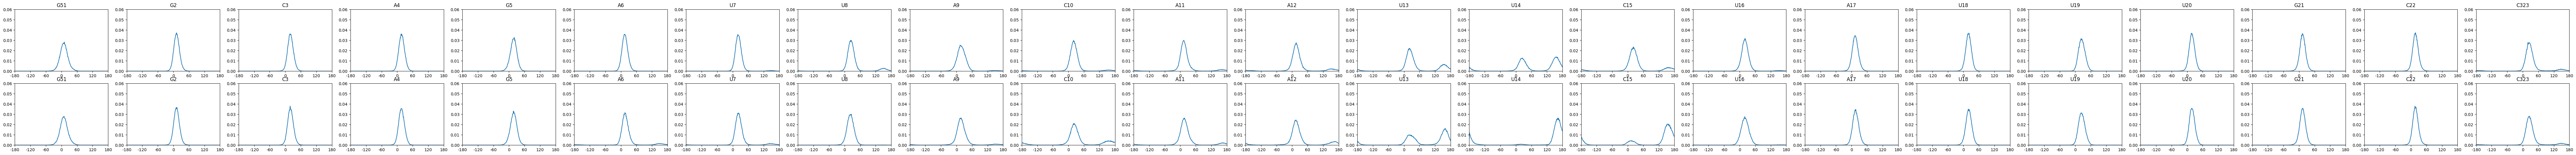

In [4]:
fig, ax = plt.subplots(2, len(ps_free))
fig.set_size_inches(112, 6)

for i_ps, ps in enumerate([ps_free, ps_cmd]):
    for rna_residue_index in range(len(ps)):
        ax[i_ps, rna_residue_index].plot(range(-180, 180), make_histogram(ps[rna_residue_index]))

        ax[i_ps, rna_residue_index].set_title(gleap_target_free.topology.residue(rna_residue_index))
        ax[i_ps, rna_residue_index].set_xlim(-180, 180)
        ax[i_ps, rna_residue_index].set_ylim(0, 0.06)
        ax[i_ps, rna_residue_index].set_xticks([-180+val*60 for val in range(7)], [-180+val*60 for val in range(7)])

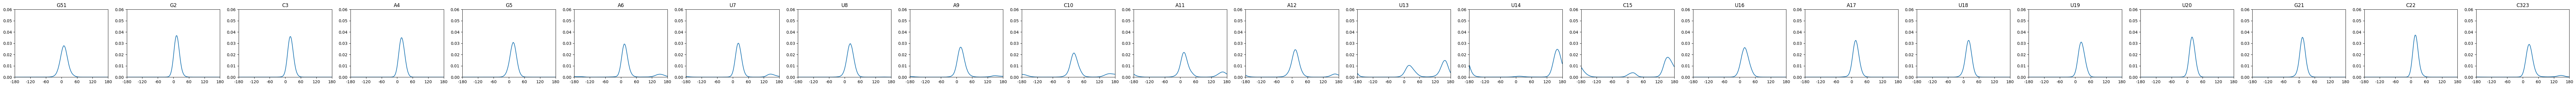

In [5]:
fig, ax = plt.subplots(1, len(ps_free))
fig.set_size_inches(112, 3)

for rna_residue_index in range(len(ps_pacs[0])):
    ps = []
    for _ps in ps_pacs:
        ps.extend(_ps[rna_residue_index])
    ps = np.array(ps)
    ax[rna_residue_index].plot(range(-180, 180), make_histogram(ps))

    ax[rna_residue_index].set_title(gleap_target_free.topology.residue(rna_residue_index))
    ax[rna_residue_index].set_xlim(-180, 180)
    ax[rna_residue_index].set_ylim(0, 0.06)
    ax[rna_residue_index].set_xticks([-180+val*60 for val in range(7)], [-180+val*60 for val in range(7)])

In [6]:
fig, ax = plt.subplots(len(ps_pacs), len(ps_pacs[0]))
fig.set_size_inches(112, 3*len(ps_pacs))

pacs_g_stds_ordered = [(31, -4.735853785240314), (7, -5.003221288882127), (33, -6.1712455762377), (36, -6.180162572537599), (0, -6.210113021586358), (30, -6.216313100489841), (9, -6.251780248769708), (38, -6.296379757436588), (27, -6.324510759445658), (40, -6.381722757539424), (32, -6.509867909636235), (34, -6.65776635690953), (10, -6.658739791058698), (22, -6.769263592911873), (23, -6.849960467272739), (37, -7.002564078210508), (39, -7.054840715656249), (15, -7.172226729945082), (5, -7.203806460971266), (2, -7.232743697331362), (18, -7.233791833157946), (41, -7.341685708162548), (16, -7.378704623377679), (21, -7.588823614916845), (3, -7.599282496154251), (26, -7.6169525908216595), (24, -7.6582205055259855), (43, -7.7721566819200385), (47, -7.86607703613511), (25, -8.044603801531192), (19, -8.180487490175555), (1, -8.352104957473054), (4, -8.363452409766765), (35, -8.62376698137324), (48, -8.897102024270128), (17, -8.951450697043283), (12, -9.22416800717634), (28, -9.303069328921787), (6, -9.447668263756011), (20, -9.565845849483889), (44, -9.82198602519813), (8, -10.025183483140054), (11, -10.130897652222377), (45, -10.193345069283023), (14, -10.211764009023716), (42, -10.472280087159808), (29, -10.48809448472755), (49, -11.643817506456426), (46, -12.089479389986025), (13, -12.823817580590074)]

ax_row = 0
for trial, g_std in pacs_g_stds_ordered:
    for rna_residue_index in range(len(ps_pacs[0])):
        ax[ax_row, rna_residue_index].plot(range(-180, 180), make_histogram(ps_pacs[trial][rna_residue_index]))

        ax[ax_row, rna_residue_index].set_title(f"t{trial}-{gleap_target_complex.topology.residue(rna_residue_index)}")
        ax[ax_row, rna_residue_index].set_xlim(-180, 180)
        ax[ax_row, rna_residue_index].set_ylim(0, 0.06)
        ax[ax_row, rna_residue_index].set_xticks([-180+val*60 for val in range(7)], [-180+val*60 for val in range(7)])
    ax_row += 1

11 free -180 0.0016643328665733148
11 free -175 0.0015123024604920985
11 free -170 0.0014482896579315866
11 free -165 0.0015843168633726747
11 free -160 0.0013602720544108823
11 free -155 0.001280256051210242
11 free -150 0.0010082016403280658
11 free -145 0.0007201440288057612
11 free -140 0.000584116823364673
11 free -135 0.0003120624124824965
11 free -130 0.00019203840768153632
11 free -125 0.00010402080416083216
11 free -120 8.001600320064013e-05
11 free -115 5.601120224044809e-05
11 free -110 2.4004800960192037e-05
11 free -105 7.201440288057611e-05
11 free -100 3.200640128025605e-05
11 free -95 1.6003200640128026e-05
11 free -90 0.0
11 free -85 8.001600320064013e-06
11 free -80 1.6003200640128026e-05
11 free -75 2.4004800960192037e-05
11 free -70 2.4004800960192037e-05
11 free -65 5.601120224044809e-05
11 free -60 3.200640128025605e-05
11 free -55 5.601120224044809e-05
11 free -50 6.40128025605121e-05
11 free -45 0.00016003200640128025
11 free -40 0.00022404480896179231
11 free -

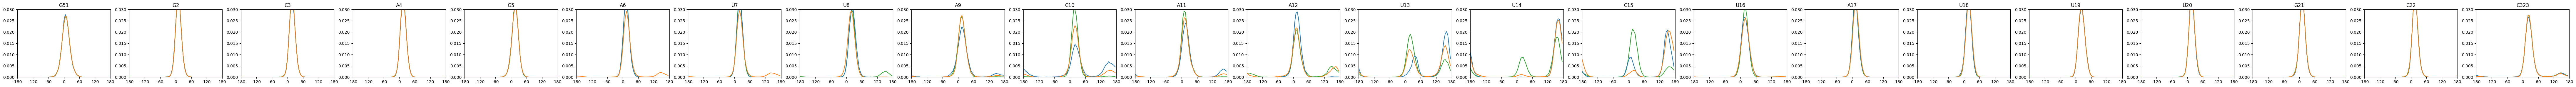

In [7]:
metastabled_trajs_concat = pickle.load(open("./pickle-cache/pca_tetranucl/metastabled_trajs_concat_2.pickle", "rb"))

fig, ax = plt.subplots(1, len(ps_cmd))
fig.set_size_inches(112, 3)

for rna_residue_index in range(len(ps_cmd)):
    xs = range(-180, 180, 5)
    
    hist_ps_free_rna_residue = make_histogram(ps_free[rna_residue_index, metastabled_trajs_concat==0]).reshape(-1, 5).mean(axis=1)
    hist_ps_0_rna_residue    = make_histogram(ps_cmd [rna_residue_index, metastabled_trajs_concat==0]).reshape(-1, 5).mean(axis=1)
    hist_ps_1_rna_residue    = make_histogram(ps_cmd [rna_residue_index, metastabled_trajs_concat==1]).reshape(-1, 5).mean(axis=1)

    if rna_residue_index in [11, 12, 13, 14]:
        for x, ratio in zip(xs, hist_ps_free_rna_residue):
            print(rna_residue_index, "free", x, ratio)
        for x, ratio in zip(xs, hist_ps_0_rna_residue):
            print(rna_residue_index, "   0", x, ratio)
        for x, ratio in zip(xs, hist_ps_1_rna_residue):
            print(rna_residue_index, "   1", x, ratio)
    
    ax[rna_residue_index].plot(xs, hist_ps_free_rna_residue, color="tab:green")
    ax[rna_residue_index].plot(xs, hist_ps_0_rna_residue, color="tab:blue")
    ax[rna_residue_index].plot(xs, hist_ps_1_rna_residue, color="tab:orange")

    ax[rna_residue_index].set_title(gleap_target_complex.topology.residue(rna_residue_index))
    ax[rna_residue_index].set_xlim(-180, 180)
    ax[rna_residue_index].set_ylim(0, 0.03)
    ax[rna_residue_index].set_xticks([-180+val*60 for val in range(7)], [-180+val*60 for val in range(7)])

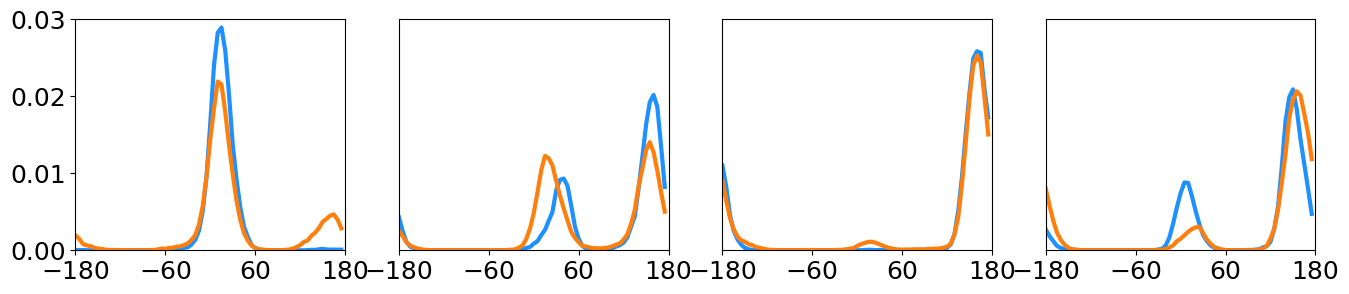

In [8]:
metastabled_trajs_concat = pickle.load(open("./pickle-cache/pca_tetranucl/metastabled_trajs_concat_2.pickle", "rb"))

fig, ax = plt.subplots(1, 4)
fig.set_size_inches(16, 3)

for rna_residue_index in range(11, 15):
    xs = range(-180, 180, 5)
    
    hist_ps_0_rna_residue    = make_histogram(ps_cmd [rna_residue_index, metastabled_trajs_concat==0]).reshape(-1, 5).mean(axis=1)
    hist_ps_1_rna_residue    = make_histogram(ps_cmd [rna_residue_index, metastabled_trajs_concat==1]).reshape(-1, 5).mean(axis=1)

    ax[rna_residue_index-11].plot(xs, hist_ps_0_rna_residue, color="#1E90FF", linewidth=3)
    ax[rna_residue_index-11].plot(xs, hist_ps_1_rna_residue, color="tab:orange", linewidth=3)

    # ax[rna_residue_index-11].set_title(gleap_target_complex.topology.residue(rna_residue_index))
    ax[rna_residue_index-11].set_xlim(-180, 180)
    ax[rna_residue_index-11].set_ylim(0, 0.03)

    if rna_residue_index == 11:
        ax[rna_residue_index-11].set_xticks([-180+val*120 for val in range(4)])
        ax[rna_residue_index-11].tick_params(axis='x', labelsize=18)
        ax[rna_residue_index-11].set_yticks([0.01*val for val in range(4)])
        ax[rna_residue_index-11].tick_params(axis='y', labelsize=18)
    else:
        ax[rna_residue_index-11].set_xticks([-180+val*120 for val in range(4)])
        ax[rna_residue_index-11].tick_params(axis='x', labelsize=18)
        ax[rna_residue_index-11].set_yticks([], [])